In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [3]:
# Load the sales and calendar datasets
sales = pd.read_csv("../data/raw/sales_train_validation.csv")
calendar = pd.read_csv("../data/raw/calendar.csv")

print("Sales shape:", sales.shape)
print("Calendar shape:", calendar.shape)

sales.head()

Sales shape: (30490, 1919)
Calendar shape: (1969, 14)


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1904,d_1905,d_1906,d_1907,d_1908,d_1909,d_1910,d_1911,d_1912,d_1913
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,3,0,1,1,1,3,0,1,1
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,2,1,1,1,0,1,1,1
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,5,4,1,0,1,3,7,2
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,1,0,1,1,2,2,2,4


In [4]:
item_id = "FOODS_3_090"
store_id = "CA_3"

target = sales[
    (sales["item_id"] == item_id) &
    (sales["store_id"] == store_id)
]

print("Matching rows:", len(target))

Matching rows: 1


In [5]:
day_columns = [
    col for col in sales.columns
    if col.startswith("d_")
]

target_daily = target[day_columns].T
target_daily.columns = ["sales"]

target_daily["d"] = target_daily.index
target_daily = target_daily.merge(
    calendar[["d", "date"]],
    on="d",
    how="left"
)

target_daily["date"] = pd.to_datetime(target_daily["date"])

target_daily = (
    target_daily[["date", "sales"]]
    .set_index("date")
    .sort_index()
)

target_daily.head()

,sales
date,
2011-01-29,108
2011-01-30,132
2011-01-31,102
2011-02-01,120
2011-02-02,106


In [6]:
test_days = 28

train = target_daily.iloc[:-test_days].copy()
test = target_daily.iloc[-test_days:].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Training period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

Training observations: 1885
Testing observations: 28
Training period: 2011-01-29 00:00:00 to 2016-03-27 00:00:00
Testing period: 2016-03-28 00:00:00 to 2016-04-24 00:00:00


In [7]:
hw_model = ExponentialSmoothing(
    train["sales"].astype(float),
    trend="add",
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
)

hw_fit = hw_model.fit(optimized=True)
hw_forecast = hw_fit.forecast(len(test))

print("Forecast length:", len(hw_forecast))
print("Test length:", len(test))

C:\Users\victo\AppData\Roaming\Python\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


Forecast length: 28
Test length: 28


In [8]:
hw_mae = mean_absolute_error(
    test["sales"],
    hw_forecast
)

hw_rmse = np.sqrt(
    mean_squared_error(
        test["sales"],
        hw_forecast
    )
)

hw_wape = (
    np.abs(
        test["sales"].to_numpy()
        - hw_forecast.to_numpy()
    ).sum()
    / test["sales"].sum()
) * 100

print("Holt-Winters Performance")
print("------------------------")
print("MAE :", round(hw_mae, 2))
print("RMSE:", round(hw_rmse, 2))
print("WAPE:", round(hw_wape, 2), "%")

Holt-Winters Performance
------------------------
MAE : 61.1
RMSE: 63.62
WAPE: 55.36 %


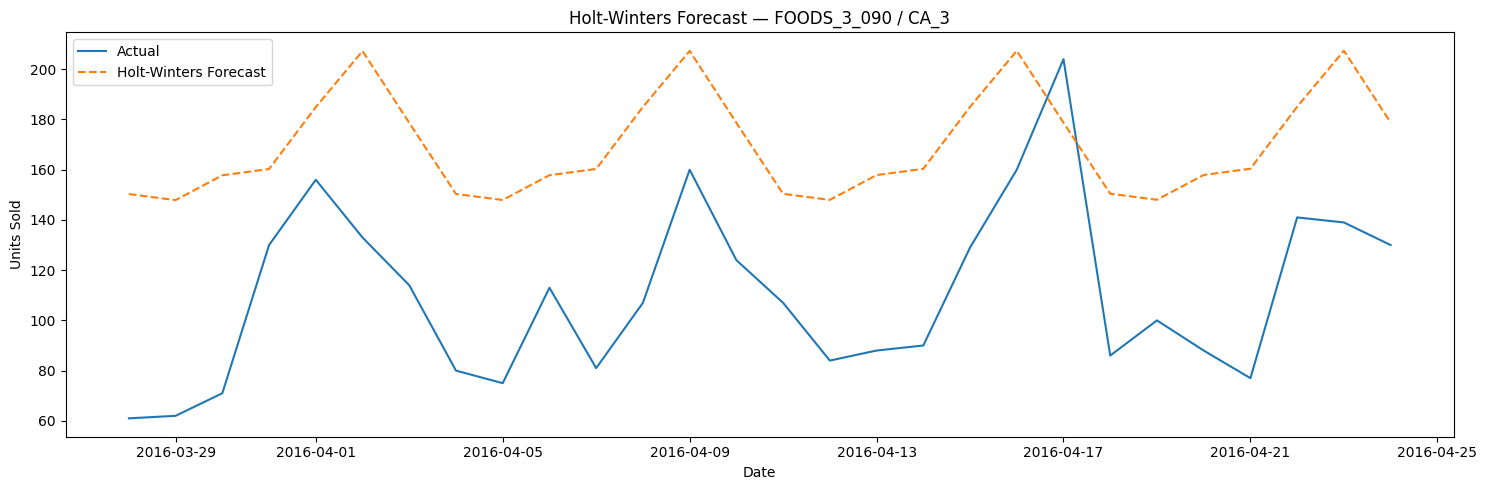

In [9]:
plt.figure(figsize=(15, 5))

plt.plot(
    test.index,
    test["sales"],
    label="Actual"
)

plt.plot(
    test.index,
    hw_forecast,
    label="Holt-Winters Forecast",
    linestyle="--"
)

plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.title("Holt-Winters Forecast — FOODS_3_090 / CA_3")
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
comparison = pd.DataFrame({
    "Model": [
        "Naive",
        "Seasonal Naive",
        "Holt-Winters"
    ],
    "MAE": [
        101.642857,
        32.642857,
        hw_mae
    ],
    "RMSE": [
        107.230726,
        44.550934,
        hw_rmse
    ],
    "WAPE (%)": [
        92.103560,
        29.579288,
        hw_wape
    ]
})

comparison.round(2)

,Model,MAE,RMSE,WAPE (%)
0,Naive,101.64,107.23,92.10
1,Seasonal Naive,32.64,44.55,29.58
2,Holt-Winters,61.10,63.62,55.36


In [11]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

hw_model_2 = ExponentialSmoothing(
    train["sales"].astype(float),
    trend="add",
    seasonal="add",
    seasonal_periods=7,
    damped_trend=True,
    initialization_method="estimated"
)

hw_fit_2 = hw_model_2.fit(optimized=True)

hw_forecast_2 = hw_fit_2.forecast(len(test))

hw_mae_2 = mean_absolute_error(
    test["sales"], hw_forecast_2
)

hw_rmse_2 = np.sqrt(
    mean_squared_error(test["sales"], hw_forecast_2)
)

hw_wape_2 = (
    np.abs(
        test["sales"].to_numpy()
        - hw_forecast_2.to_numpy()
    ).sum()
    / test["sales"].sum()
) * 100

print("Damped Holt-Winters Performance")
print("--------------------------------")
print("MAE :", round(hw_mae_2, 2))
print("RMSE:", round(hw_rmse_2, 2))
print("WAPE:", round(hw_wape_2, 2), "%")

Damped Holt-Winters Performance
--------------------------------
MAE : 60.79
RMSE: 63.32
WAPE: 55.09 %


C:\Users\victo\AppData\Roaming\Python\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


In [19]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Calculate metrics for the Naive model
naive_mae = mean_absolute_error(test["sales"], naive_forecast)
naive_rmse = np.sqrt(mean_squared_error(test["sales"], naive_forecast))
naive_wape = (
    np.abs(test["sales"].to_numpy() - np.asarray(naive_forecast)).sum()
    / np.abs(test["sales"].to_numpy()).sum()
) * 100

# Calculate metrics for the Seasonal Naive model
seasonal_mae = mean_absolute_error(test["sales"], seasonal_naive_forecast)
seasonal_rmse = np.sqrt(
    mean_squared_error(test["sales"], seasonal_naive_forecast)
)
seasonal_wape = (
    np.abs(
        test["sales"].to_numpy()
        - np.asarray(seasonal_naive_forecast)
    ).sum()
    / np.abs(test["sales"].to_numpy()).sum()
) * 100

# Build the comparison table
comparison = pd.DataFrame({
    "Model": [
        "Naive",
        "Seasonal Naive",
        "Holt-Winters",
        "Damped Holt-Winters"
    ],
    "MAE": [
        naive_mae,
        seasonal_mae,
        hw_mae,
        hw_mae_2
    ],
    "RMSE": [
        naive_rmse,
        seasonal_rmse,
        hw_rmse,
        hw_rmse_2
    ],
    "WAPE (%)": [
        naive_wape,
        seasonal_wape,
        hw_wape,
        hw_wape_2
    ]
})

comparison = comparison.sort_values("WAPE (%)")
comparison.round(2)

NameError: name 'naive_forecast' is not defined

In [14]:
print("mae:", "mae" in globals())
print("rmse:", "rmse" in globals())
print("wape:", "wape" in globals())

print("seasonal_mae:", "seasonal_mae" in globals())
print("hw_mae:", "hw_mae" in globals())
print("hw_mae_2:", "hw_mae_2" in globals())

mae: False
rmse: False
wape: False
seasonal_mae: False
hw_mae: True
hw_mae_2: True


In [20]:
[name for name in globals()
 if "forecast" in name.lower()]

['hw_forecast', 'hw_forecast_2']

In [21]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Actual sales
actual = test["sales"].to_numpy(dtype=float)

# Recreate Naive forecast using the last training value
naive_forecast = np.repeat(float(train["sales"].iloc[-1]), len(test))

# Recreate Seasonal Naive forecast using the previous week's sales
seasonal_values = pd.concat([train["sales"], test["sales"]])
seasonal_forecast = seasonal_values.iloc[
    len(train) - 7 : len(train) - 7 + len(test)
].to_numpy(dtype=float)

def evaluate_model(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    wape = np.abs(actual - predicted).sum() / np.abs(actual).sum() * 100
    return [mae, rmse, wape]

comparison = pd.DataFrame(
    [
        ["Naive", *evaluate_model(actual, naive_forecast)],
        ["Seasonal Naive", *evaluate_model(actual, seasonal_forecast)],
        ["Holt-Winters", *evaluate_model(actual, hw_forecast)],
        ["Damped Holt-Winters", *evaluate_model(actual, hw_forecast_2)],
    ],
    columns=["Model", "MAE", "RMSE", "WAPE (%)"]
)

comparison = comparison.sort_values("WAPE (%)").reset_index(drop=True)
comparison.round(2)

,Model,MAE,RMSE,WAPE (%)
0,Seasonal Naive,29.36,39.76,26.60
1,Damped Holt-Winters,60.79,63.32,55.09
2,Holt-Winters,61.10,63.62,55.36
3,Naive,101.64,107.23,92.10
